In [24]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

from sklearn.neighbors import KNeighborsClassifier

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab_AI 영상처리


In [25]:
# * 학습할 이미지 데이터 준비

# X :: 사과, 바나나 사진 파일
names = [
    'apple1.png',
    'apple2.png',
    'apple3.png',
    'banana1.png',
    'banana2.png',
    'banana3.png'
]

# X = [[img1 정보], [img2 정보], ...]
X = []
for n in names:
  img = cv2.imread('picture/fruits/' + n)

  # 모든 이미지 파일에 대해, 크기를 통일
  img = cv2.resize(img, (16, 16))

  # 머신러닝 모델에는 문제(요인, X)의 값을 2차원 배열
  #   img 배열값을 1차원으로
  data = img.reshape(-1)
  X.append(data)
X = np.array(X)

# Y :: 군집 데이터 (0은 사과, 1은 바나나)
Y = np.array([0, 0, 0, 1, 1, 1])

In [26]:
# KNN 모델 생성 + 학습
model = KNeighborsClassifier()
model.fit(X, Y)

KNeighborsClassifier()

In [27]:
# 테스트용 사진 불러오기
test = cv2.imread('picture/fruits/test.png')
test = cv2.resize(test, (16, 16))   # 이미지 크기 통일
test_data = test.reshape(1, -1)     # 3차원 -> 2차원

바나나입니다.


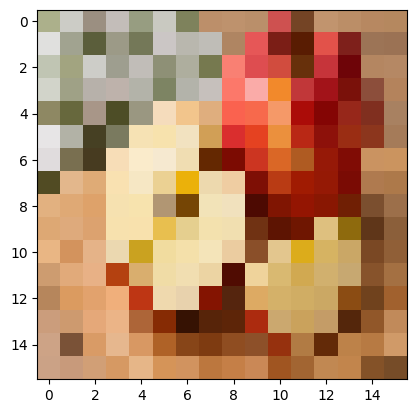

In [29]:
# 예측 진행
# "해당 이미지가 사과(0)인가, 바나나(1)인가?"
result = model.predict(test_data)

if result == 0:
  print('사과입니다.')
else:
  print('바나나입니다.')

test_rgb = cv2.cvtColor(
    test,
    cv2.COLOR_BGR2RGB
)
plt.imshow(test_rgb)
plt.show()